# Dealer Gamma 05 — pinning: does settlement gravitate to the dealer-long-gamma strike?

Pre-registration: `discussions/Dealer_Gamma/001_claude_branch_preregistration.md`. Code: `src/data_engineering/modeling/dealer_gamma.py`.

For every 08:00 UTC expiry: strike table at 05:00 for that expiry (strikes within ±5% of S). Pin strike K by rule (`long_gamma` primary, `long_gamma_noblock`, `max_position`, `short_gamma` control); placebo $K' = 2S_{05} - K$. Settlement proxy X = 07:30–08:00 index average. $\Delta = (|X-K| - |X-K'|)/S_{05}$ in bp; negative = settled closer to the pin than to the placebo.

**H:** mean Δ < 0 for `long_gamma` and `max_position`; `short_gamma` Δ ≥ 0. Bootstrap over expiries. PASS = both currencies, primary group `all`, rule `long_gamma`.

In [1]:
from pathlib import Path
import json, os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import dealer_gamma as dg

ENV = dg.notebook_env('05', PROJECT_ROOT)
OUT, CACHE, HIST = ENV['out'], ENV['cache'], ENV['history']
PERIODS = ['discovery'] + (['holdout'] if ENV['holdout'] else [])
print(dg.VERSION, '| synthetic' if ENV['synthetic'] else '', '| periods', PERIODS)
print('data', ENV['data_root']); print('cache', CACHE); print('out', OUT)

DG-0.1.0  | periods ['discovery']
data D:\MarketData\Deribit
cache D:\MarketData\Deribit\derived\dealer_gamma
out D:\Projects\deribit_market_data\notebooks\Dealer_Gamma\05


In [2]:
EV, TS = [], []
for c in dg.CURRENCIES:
    d = dg.load_cache(CACHE, c)
    ev = dg.pin_events(d['pins'], d['settle'])
    EV.append(ev)
    for per in PERIODS:
        TS.append(dg.pin_test(ev, per))
EV = pd.concat(EV); TS = pd.concat(TS)
EV.to_csv(OUT / '05_events.csv', index=False, float_format='%.6g'); TS.to_csv(OUT / '05_tests.csv', index=False)
print(EV.groupby(['currency', 'period', 'type']).expiry_date.nunique().unstack(fill_value=0))
display(TS.pivot_table(index=['period', 'group', 'rule'], columns='currency', values=['mean_delta_bp', 'p_one_sided']).round(3))

type                daily  monthly  quarterly  weekly
currency period                                      
BTC      burn_in      155        4          2      20
         discovery    313        8          4      40
         holdout      439       11          5      57
ETH      burn_in      155        4          2      20
         discovery    313        8          4      40
         holdout      439       11          5      57


mean_delta_bp         p_one_sided       
currency                                       BTC     ETH         BTC    ETH
period    group   rule                                                       
discovery all     long_gamma                -3.684 -10.328       0.224  0.067
                  long_gamma_noblock        -2.940  -7.637       0.276  0.131
                  max_position              -6.758   2.373       0.110  0.618
                  short_gamma                1.277   5.906       0.378  0.209
          daily   long_gamma                -4.177  -9.603       0.200  0.088
                  long_gamma_noblock        -2.450  -6.625       0.331  0.175
                  max_position              -7.993   1.203       0.070  0.548
                  short_gamma               -2.636   5.585       0.740  0.242
          friday  long_gamma                -0.718 -15.023       0.482  0.226
                  long_gamma_noblock        -5.986 -14.604       0.344  0.264
                  max_position               0.679   9.416       0.509  0.696
                  short_gamma               24.828   7.839       0.043  0.322
          monthly long_gamma               -19.985  -0.676       0.251  0.511
                  long_gamma_noblock        33.713  35.869       0.882  0.736
                  max_position              23.107 -21.713       0.722  0.340
                  short_gamma               88.684   4.238       0.008  0.471
          weekly  long_gamma                -7.576 -15.618       0.321  0.256
                  long_gamma_noblock       -11.305 -19.587       0.241  0.217
                  max_position              -5.468  10.251       0.373  0.677
                  short_gamma               16.970  17.307       0.108  0.156

In [3]:
prim = TS[(TS.group == 'all') & (TS.rule == 'long_gamma')]
dec = dg.decide(prim, ['group', 'rule'])
secondary = dg.decide(TS[TS.rule.isin(['long_gamma', 'max_position', 'long_gamma_noblock'])], ['group', 'rule'])
dg.dump({'registration': dg.registration(), 'decision_primary': dec, 'secondary': secondary}, OUT / '05_decision.json')
print(json.dumps(dec, indent=2))

{
  "discovery": {
    "('all', 'long_gamma')": "FAIL"
  },
  "holdout": "NOT_RUN"
}


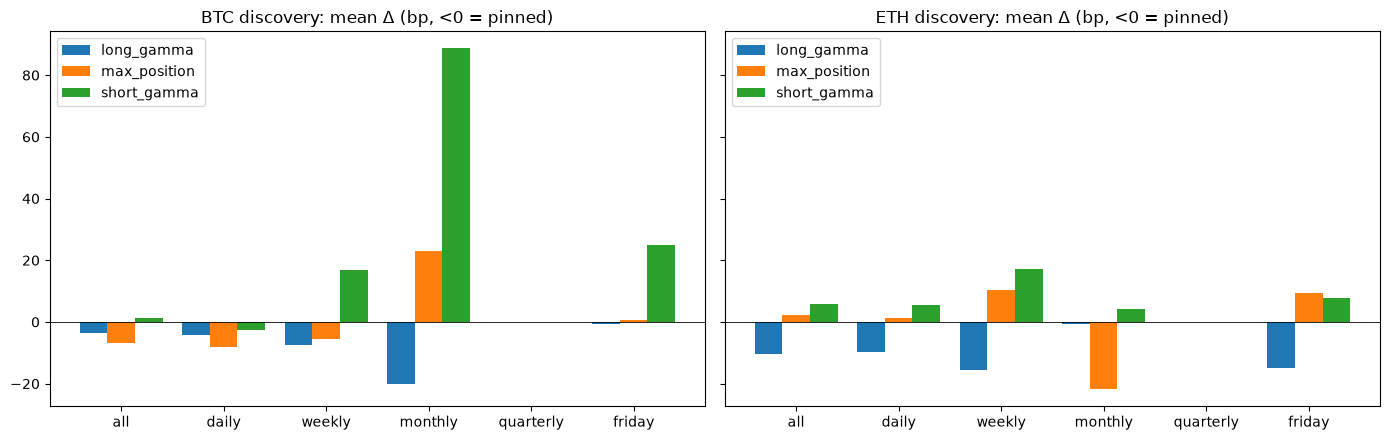

In [4]:
fig, ax = plt.subplots(1, len(dg.CURRENCIES), figsize=(14, 4.5), sharey=True)
order = ['all', 'daily', 'weekly', 'monthly', 'quarterly', 'friday']
for j, c in enumerate(dg.CURRENCIES):
    z = TS[(TS.currency == c) & (TS.period == 'discovery')]
    for k, rule in enumerate(['long_gamma', 'max_position', 'short_gamma']):
        w = z[z.rule == rule].set_index('group').reindex(order)
        ax[j].bar(np.arange(len(order)) + 0.27 * k, w.mean_delta_bp, width=0.27, label=rule)
    ax[j].axhline(0, color='k', lw=0.6); ax[j].set_xticks(np.arange(len(order)) + 0.27, order)
    ax[j].set_title(f'{c} discovery: mean Δ (bp, <0 = pinned)'); ax[j].legend()
plt.tight_layout(); plt.savefig(OUT / '05_pinning.png', dpi=110); plt.show()